# Heart Disease Prediction
Exploratory data analysis, preprocessing and classification models on `heart.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

pd.set_option("display.width", 115)
pd.set_option("display.max_columns", 20)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("heart.csv")
print(df)

     Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR ExerciseAngina  Oldpeak ST_Slope  \
0     40   M           ATA        140          289          0     Normal    172              N      0.0       Up   
1     49   F           NAP        160          180          0     Normal    156              N      1.0     Flat   
2     37   M           ATA        130          283          0         ST     98              N      0.0       Up   
3     48   F           ASY        138          214          0     Normal    108              Y      1.5     Flat   
4     54   M           NAP        150          195          0     Normal    122              N      0.0       Up   
..   ...  ..           ...        ...          ...        ...        ...    ...            ...      ...      ...   
913   45   M            TA        110          264          0     Normal    132              N      1.2     Flat   
914   68   M           ASY        144          193          1     Normal

In [3]:
print(df.isnull().sum())

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [5]:
print(df.describe())
print()
print(df.shape)

              Age   RestingBP  Cholesterol   FastingBS       MaxHR     Oldpeak  HeartDisease
count  918.000000  918.000000   918.000000  918.000000  918.000000  918.000000    918.000000
mean    53.510893  132.396514   198.799564    0.233115  136.809368    0.887364      0.553377
std      9.432617   18.514154   109.384145    0.423046   25.460334    1.066570      0.497414
min     28.000000    0.000000     0.000000    0.000000   60.000000   -2.600000      0.000000
25%     47.000000  120.000000   173.250000    0.000000  120.000000    0.000000      0.000000
50%     54.000000  130.000000   223.000000    0.000000  138.000000    0.600000      1.000000
75%     60.000000  140.000000   267.000000    0.000000  156.000000    1.500000      1.000000
max     77.000000  200.000000   603.000000    1.000000  202.000000    6.200000      1.000000

(918, 12)


In [6]:
print("Duplicate rows:", df.duplicated().sum())
print(df.columns)

Duplicate rows: 0
Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR',
       'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease'],
      dtype='object')


## Univariate analysis and data cleaning

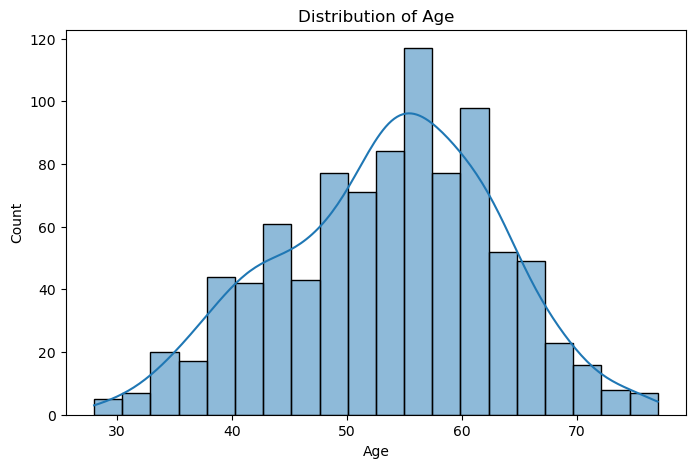

In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Age", bins=20, kde=True)
plt.title("Distribution of Age")
plt.show()

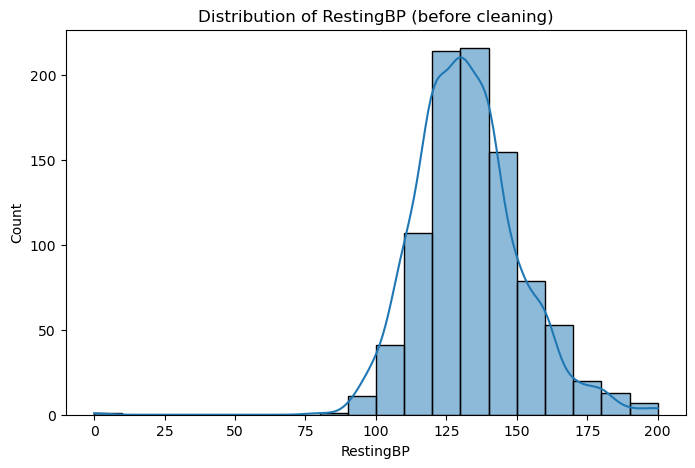

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="RestingBP", bins=20, kde=True)
plt.title("Distribution of RestingBP (before cleaning)")
plt.show()

In [9]:
zero_bp = (df["RestingBP"] == 0).sum()
print(f"Number of zero values in RestingBP : {zero_bp}")

df["RestingBP"] = df["RestingBP"].replace(0, np.nan)
df["RestingBP"] = df["RestingBP"].fillna(df["RestingBP"].median())

Number of zero values in RestingBP : 1


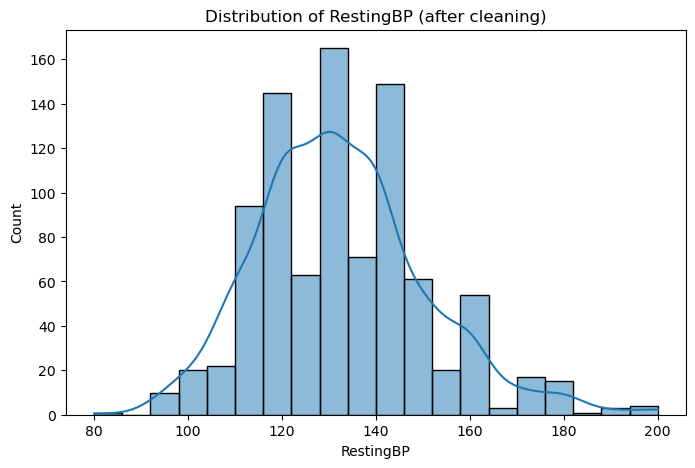

In [10]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="RestingBP", bins=20, kde=True)
plt.title("Distribution of RestingBP (after cleaning)")
plt.show()

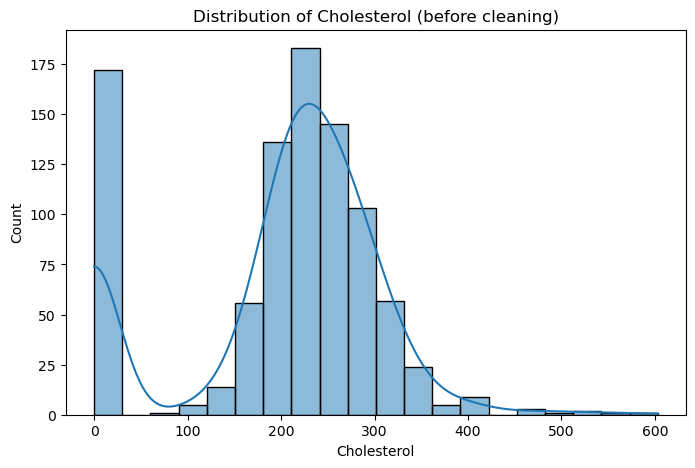

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Cholesterol", bins=20, kde=True)
plt.title("Distribution of Cholesterol (before cleaning)")
plt.show()

In [12]:
zero_count = (df["Cholesterol"] == 0).sum()
print(f"Number of missing/zero values : {zero_count}")

df["Cholesterol"] = df["Cholesterol"].replace(0, np.nan)
df["Cholesterol"] = df["Cholesterol"].fillna(df["Cholesterol"].median())

Number of missing/zero values : 172


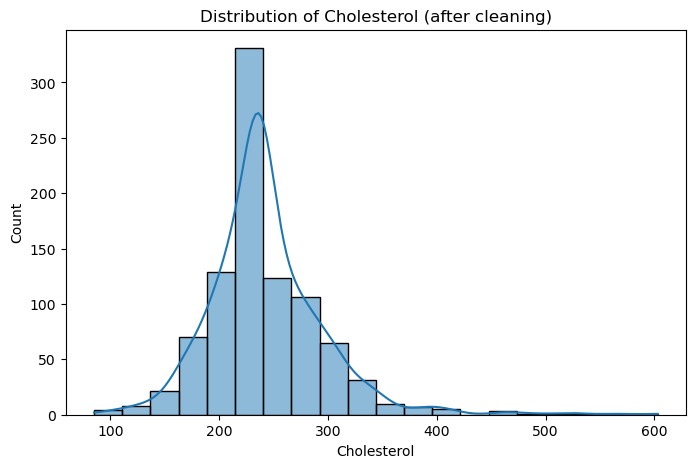

In [13]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Cholesterol", bins=20, kde=True)
plt.title("Distribution of Cholesterol (after cleaning)")
plt.show()

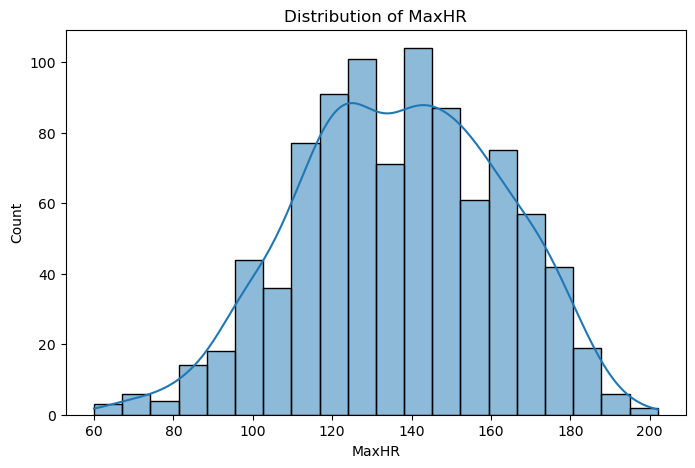

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="MaxHR", bins=20, kde=True)
plt.title("Distribution of MaxHR")
plt.show()

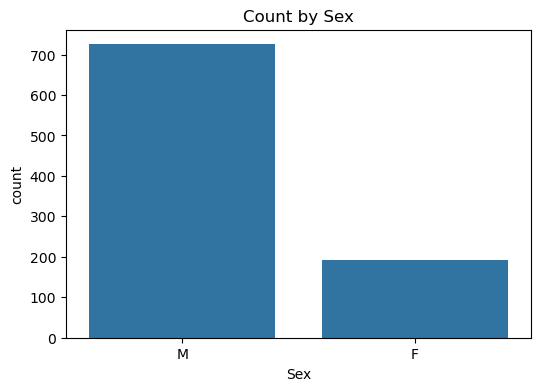

In [15]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Sex")
plt.title("Count by Sex")
plt.show()

## Bivariate analysis

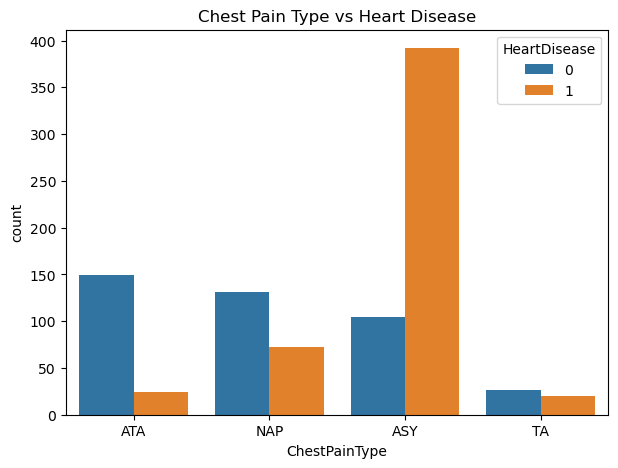

In [16]:
plt.figure(figsize=(7, 5))
sns.countplot(x=df["ChestPainType"], hue=df["HeartDisease"])
plt.title("Chest Pain Type vs Heart Disease")
plt.show()

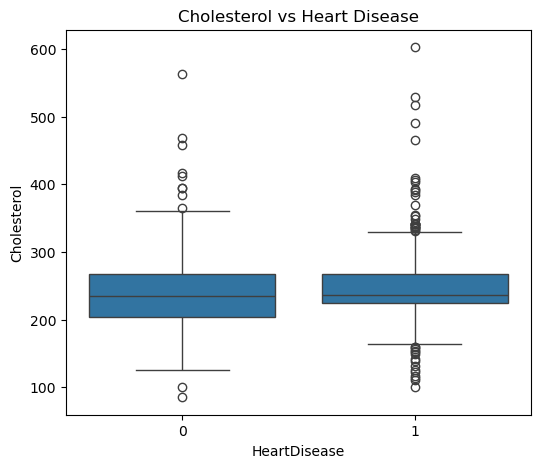

In [17]:
plt.figure(figsize=(6, 5))
sns.boxplot(x="HeartDisease", y="Cholesterol", data=df)
plt.title("Cholesterol vs Heart Disease")
plt.show()

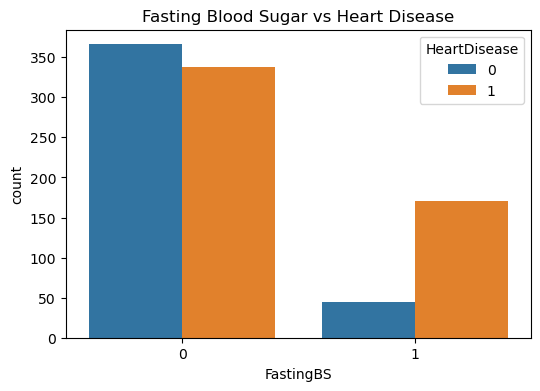

In [18]:
plt.figure(figsize=(6, 4))
sns.countplot(x=df["FastingBS"], hue=df["HeartDisease"])
plt.title("Fasting Blood Sugar vs Heart Disease")
plt.show()

## Correlation matrix

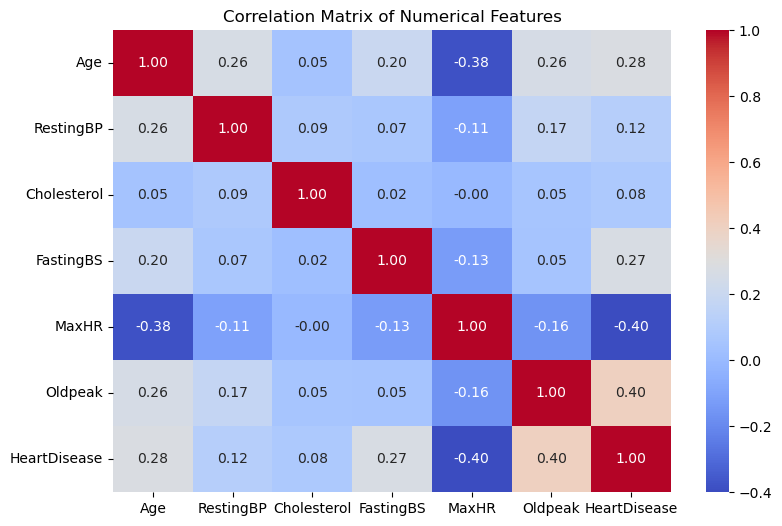

In [19]:
plt.figure(figsize=(9, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix of Numerical Features")
plt.show()

## Encoding categorical features

In [20]:
df_encoded = pd.get_dummies(df, drop_first=True)

# convert only the True/False dummy columns to 0/1 (keeps Oldpeak as a decimal)
bool_cols = df_encoded.select_dtypes(include="bool").columns
df_encoded[bool_cols] = df_encoded[bool_cols].astype(int)

print(df_encoded)

     Age  RestingBP  Cholesterol  FastingBS  MaxHR  Oldpeak  HeartDisease  Sex_M  ChestPainType_ATA  \
0     40      140.0        289.0          0    172      0.0             0      1                  1   
1     49      160.0        180.0          0    156      1.0             1      0                  0   
2     37      130.0        283.0          0     98      0.0             0      1                  1   
3     48      138.0        214.0          0    108      1.5             1      0                  0   
4     54      150.0        195.0          0    122      0.0             0      1                  0   
..   ...        ...          ...        ...    ...      ...           ...    ...                ...   
913   45      110.0        264.0          0    132      1.2             1      1                  0   
914   68      144.0        193.0          1    141      3.4             1      1                  0   
915   57      130.0        131.0          0    115      1.2             1

In [21]:
print(df_encoded.columns)
print("Shape:", df_encoded.shape)

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'HeartDisease', 'Sex_M',
       'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST',
       'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up'],
      dtype='object')
Shape: (918, 16)


## Train/test split, scaling and model building

In [22]:
X = df_encoded.drop("HeartDisease", axis=1)
y = df_encoded["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train_scaled.shape)
print("Test shape:", X_test_scaled.shape)

Train shape: (734, 15)
Test shape: (184, 15)


In [23]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Support Vector Machine": SVC(),
    "K-Nearest Neighbors": KNeighborsClassifier()
}

result = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    result.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "F1 Score": round(f1, 4)
    })

results_df = pd.DataFrame(result)
print(results_df)

                    Model  Accuracy  F1 Score
0     Logistic Regression    0.8587    0.8738
1             Naive Bayes    0.8478    0.8614
2           Decision Tree    0.8098    0.8293
3  Support Vector Machine    0.8587    0.8762
4     K-Nearest Neighbors    0.8478    0.8654


In [24]:
import joblib

# Assuming 'models["Support Vector Machine"]' is your best trained model
best_model = models["Support Vector Machine"]

# Save the model and the scaler
joblib.dump(best_model, "heart_disease_model.pkl")
joblib.dump(scaler, "scaler.pkl")
print("Model and Scaler exported successfully!")


Model and Scaler exported successfully!
